# 03 – Gap Filling: linear vs cubic spline vs smoothing spline

**Purpose:** answer the project question (see the docstring of `src/mma3001/gapfill.py`): *can missing values
in CO2 readings be reasonably reliably reconstructed using interpolation?* Real readings from one sensor are hidden
and reconstructed with linear interpolation, an exact cubic spline and a smoothing spline, and the error is measured
as the gap gets longer, to find how long a gap can be filled reliably.

**How to use:** run cells in order with **Shift + Enter** using the `.venv` kernel. The gap-filling functions
live in `src/mma3001/gapfill.py` (tested in `tests/test_gapfill.py`); this notebook only applies them.
Every choice is in the **Settings** cell (section 1), and each one is listed in the decisions log in
`report/report.md` (group D). Cells marked ✍️ are for your observations and decisions.

**The development / test rule (report D1, notes 5.5.5 and 5.6.6):** sections 2–8 use the **development** data only.
Change settings and rerun as much as you like there. The **test** data is used once, in section 9, after every
choice is final. Its results are then reported as they are, and nothing is tuned afterwards.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mma3001.io import load_env
from mma3001.cleaning import remove_repeated_uploads
from mma3001.gapfill import (METHODS, BC_TYPES, prepare_series, split_dev_test, valid_gap_starts,
                             make_gap, fill_gap, evaluate)

pd.set_option("display.max_columns", 20)

---
## 1. Settings
Every choice in one place. The report column says which line of the decisions log in `report/report.md` covers it. 
Experiment uses C02 readings from the most reliable sensor from 29/02/2024 - 15/06/2024 to create a model to fill in missing readings.
These settings set gap lengths (length of data removed/ covered to test model on), spacing as well as some other parameters

In [2]:
# ---- Data ----
SENSOR = 6012002000869            # sensor with the most usable CO2 data (02_cleaning 1.1)
VARIABLE = "Carbon dioxide"
START, END = "2024-02-29", "2024-06-15"

# ---- Development / test split ----
TEST_FRACTION = 0.25              # last 25% of the period is the test part     (report D1)
BUFFER = pd.Timedelta("1D")       # excluded gap between the two parts          (D2)

# ---- Experiment ----
GAP_LENGTHS = ["10min", "30min", "1h", "2h", "4h", "8h", "24h"]                 # (D7)
N_GAPS = 200                      # random gaps per length                      (D7)
SEED = 0                          # makes the random gaps reproducible          (D7)
CONTEXT = pd.Timedelta("2h")      # readings used each side of a gap            (D6)
MAX_SPACING = pd.Timedelta("25min")  # largest allowed spacing near a gap       (D5)
LAM = 0.1                         # smoothing spline: 0.1 (chosen by examining results in following notebook)   (D10)
BC_TYPE = "not-a-knot"            # cubic spline end condition                  (D12)

# ---- Plausibility check ----
PLAUSIBLE_MIN = 400               # ppm. Indoor CO2 should not fall clearly below outdoor air
                                  # (about 420 ppm in 2024). A judgement, not a hard limit.

# ---- Final test (section 9) ----
RUN_TEST = True                 # set to True ONCE, when every choice above is final

# The settings evaluate() needs, so every experiment below uses the same ones.
SETTINGS = dict(n_gaps=N_GAPS, context=CONTEXT, max_spacing=MAX_SPACING, seed=SEED,
                lam=LAM, bc_type=BC_TYPE)

---
## 2. Load, clean and split
Cleaning as decided in `02_cleaning.ipynb` (report B1 and B2): exact repeated uploads and near-repeats are removed,
so there is one upload per sensor per measurement time (`match="time"`). Loading takes about 20 s.

In [3]:
env = remove_repeated_uploads(load_env(), match="time")
series = prepare_series(env, SENSOR, VARIABLE, start=START, end=END)
dev, test = split_dev_test(series, test_fraction=TEST_FRACTION, buffer=BUFFER)

for name, part in [("Whole series", series), ("Development", dev), ("Test", test)]:
    print(f"{name:13s} {len(part):6,} readings   {part.index.min():%d %b %Y %H:%M} – {part.index.max():%d %b %Y %H:%M}")

Whole series  13,800 readings   29 Feb 2024 17:04 – 14 Jun 2024 03:45
Development   10,251 readings   29 Feb 2024 17:04 – 18 May 2024 18:45
Test           3,415 readings   19 May 2024 18:55 – 14 Jun 2024 03:45


### 2.1 The whole series
First step of any interpolation study (notes 3.2.13): look at the data. This plot shows the test part as well.
That is fine because it shows the data, not any method's results, so no choice is being tuned on it.

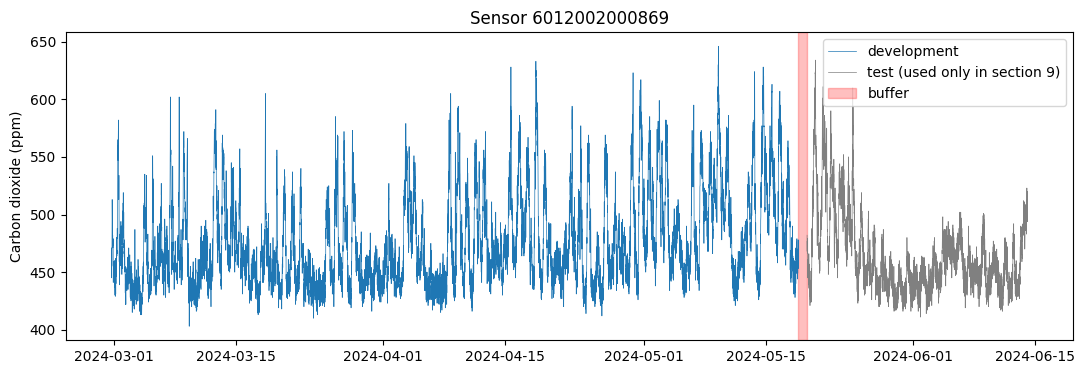

In [4]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(dev.index, dev.values, linewidth=0.5, label="development")
ax.plot(test.index, test.values, linewidth=0.5, color="grey", label="test (used only in section 9)")
ax.axvspan(dev.index.max(), test.index.min(), color="red", alpha=0.25, label="buffer")
ax.set_ylabel(f"{VARIABLE} (ppm)"); ax.set_title(f"Sensor {SENSOR}")
ax.legend(loc="upper right"); plt.show()

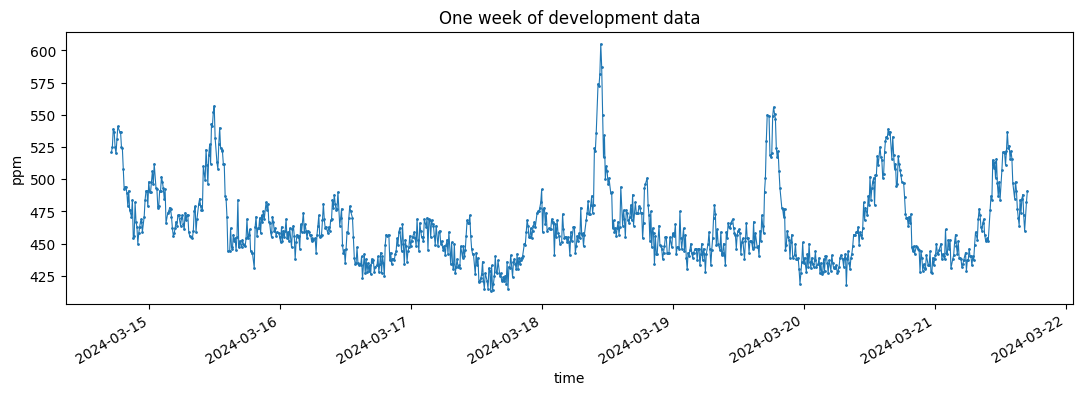

In [5]:
# One week of development data close up, to see the shape the methods have to reproduce.
week = dev[dev.index.min() + pd.Timedelta("14D") : dev.index.min() + pd.Timedelta("21D")]
ax = week.plot(figsize=(13, 4), linewidth=0.8, marker=".", markersize=2)
ax.set_ylabel("ppm"); ax.set_title("One week of development data"); plt.show()

---
## 3. Noise, spacing and daily pattern (development only)
Things that affect how hard reconstruction is (notes 3.4.16):
- **spacing:** how regular the readings are;
- **step changes:** how much CO2 changes between consecutive readings. Noise and fast changes limit how well *any* method can do;
- **daily pattern:** long gaps cover whole parts of the daily cycle, which interpolating between the two ends cannot know about.

Spacing between consecutive readings (minutes, rounded) – most common values:
time
10.0    9109
20.0    1140
30.0       1

Change between readings 10 min apart: median |change| = 8.0 ppm, 95th percentile = 24.0 ppm


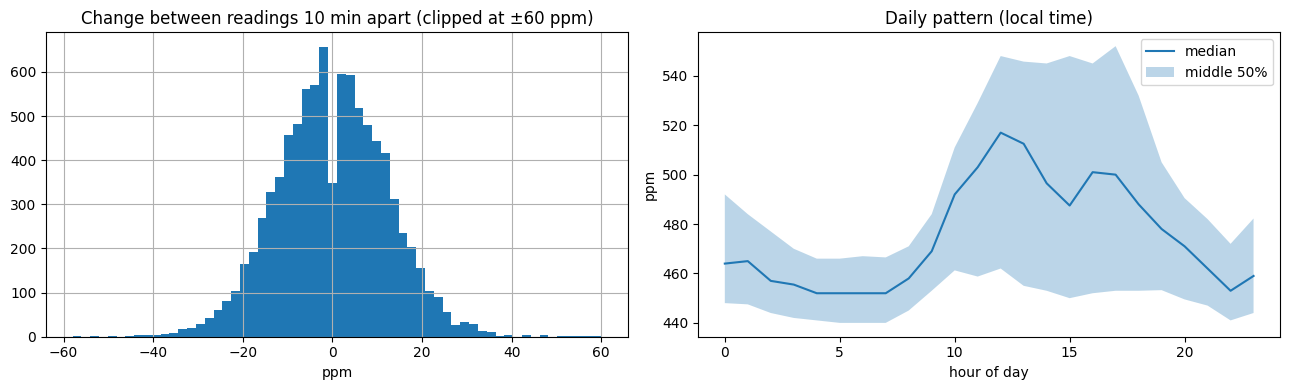

In [6]:
spacing_min = dev.index.to_series().diff().dropna().dt.total_seconds() / 60
print("Spacing between consecutive readings (minutes, rounded) – most common values:")
print(spacing_min.round().value_counts().head(6).to_string())

ten_min = spacing_min.values < 15                        # consecutive readings ~10 min apart
step = dev.diff().dropna()[ten_min]
print(f"\nChange between readings 10 min apart: median |change| = {step.abs().median():.1f} ppm, "
      f"95th percentile = {step.abs().quantile(0.95):.1f} ppm")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
step.clip(-60, 60).hist(bins=60, ax=axes[0])
axes[0].set_title("Change between readings 10 min apart (clipped at ±60 ppm)"); axes[0].set_xlabel("ppm")
by_hour = dev.groupby(dev.index.hour)
axes[1].plot(by_hour.median().index, by_hour.median().values, label="median")
axes[1].fill_between(by_hour.median().index, by_hour.quantile(0.25), by_hour.quantile(0.75), alpha=0.3, label="middle 50%")
axes[1].set_title("Daily pattern (local time)"); axes[1].set_xlabel("hour of day"); axes[1].set_ylabel("ppm"); axes[1].legend()
plt.tight_layout(); plt.show()

> ✍️ As with the env sensor readings as a whole, this trend follows the expected daily pattern given the logical expected occupancy as the day progresses.
Change between readings appears to be approximately normally distributed, also expected. 

### 3.1 Are the development and test parts alike?
If the test period behaves very differently (e.g. a holiday with nobody in the building), development results may not
carry over (notes 5.6.9). This compares the **data only**, not any method's errors.

In [7]:
def describe_part(s):
    """Summary numbers for one part of the series."""
    gaps_min = s.index.to_series().diff().dt.total_seconds() / 60
    return pd.Series({
        "readings": len(s),
        "days": (s.index.max() - s.index.min()) / pd.Timedelta("1D"),
        "mean (ppm)": s.mean(),
        "median (ppm)": s.median(),
        "std (ppm)": s.std(),
        "5th percentile": s.quantile(0.05),
        "95th percentile": s.quantile(0.95),
        "median |change| (ppm)": s.diff().abs().median(),
        "% spacings > 15 min": 100 * (gaps_min > 15).mean(),
    })

pd.DataFrame({"development": describe_part(dev), "test": describe_part(test)}).round(1)

,development,test
readings,10251.0,3415.0
days,79.1,25.4
mean (ppm),477.5,463.5
median (ppm),466.0,454.0
std (ppm),40.6,34.2
5th percentile,430.0,427.0
95th percentile,559.0,536.0
median |change| (ppm),8.0,7.0
% spacings > 15 min,11.1,7.0


Much of the core values in the comparitive statistics are close, for example thee median is  2.5% different. The spreads are also closely comparable.

---
## 4. What a reconstruction looks like
One random gap of each length, filled by all three methods using the settings above. Dots are readings kept; open
circles are the hidden readings (the truth); the shaded band is the gap. Change `EXAMPLE_SEED` to see other gaps.

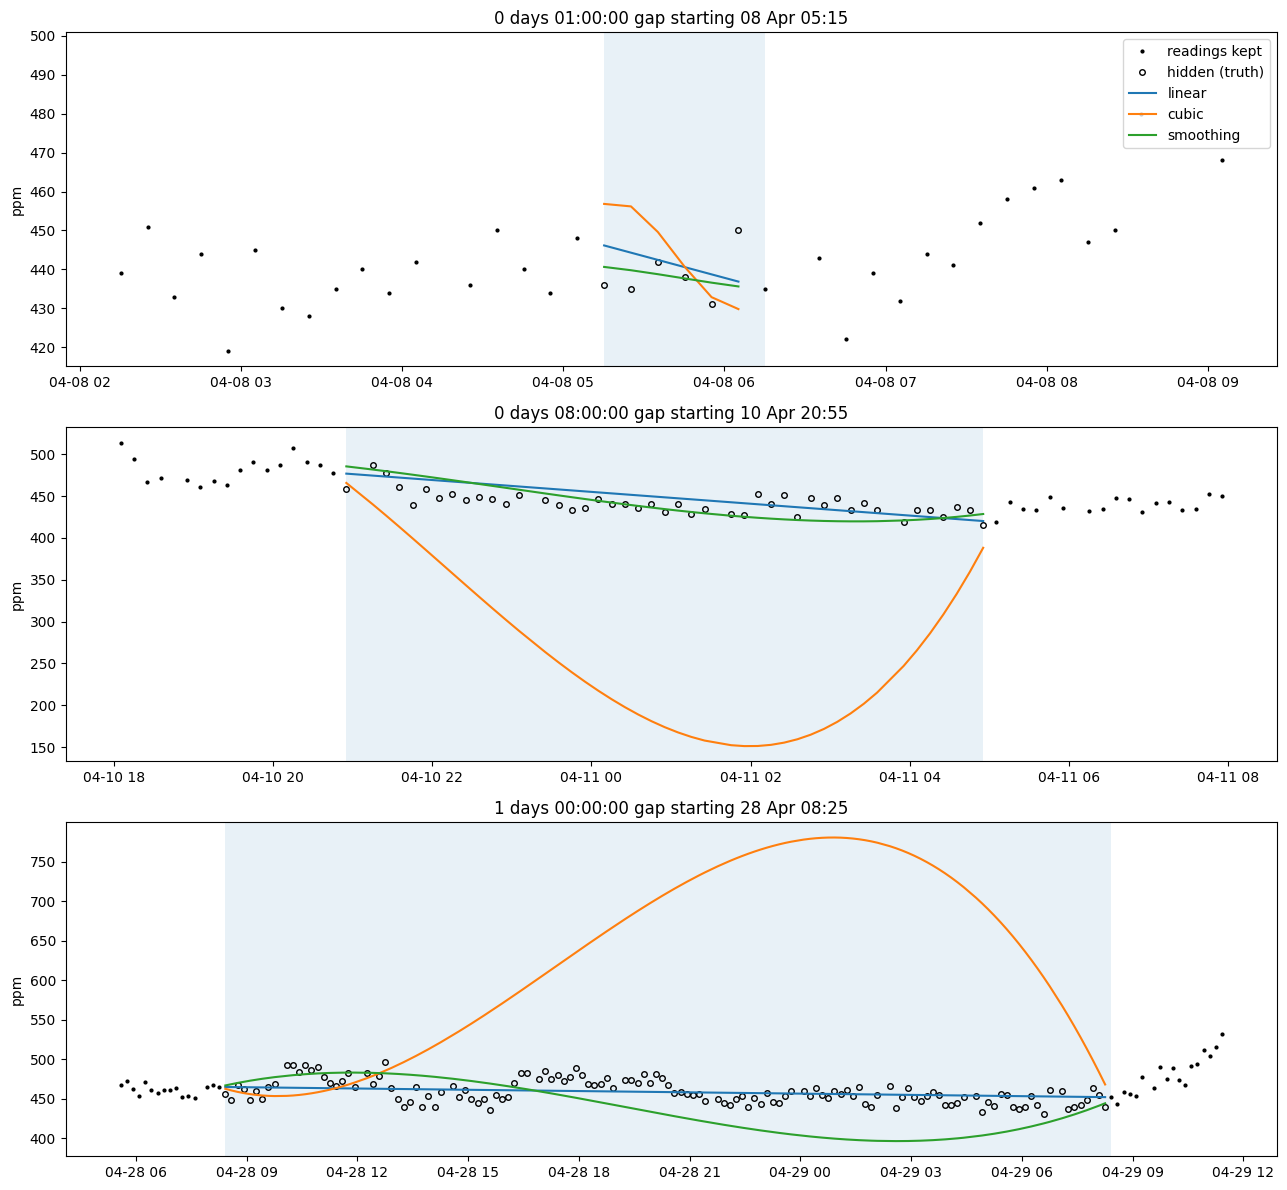

In [8]:
EXAMPLE_LENGTHS = ["1h", "8h", "24h"]
EXAMPLE_SEED = 1

def plot_example(series, gap_length, start, ax):
    """Hide one gap, fill it with every method, and plot the result."""
    gap_length = pd.Timedelta(gap_length)
    observed, truth = make_gap(series, start, gap_length)
    margin = CONTEXT + pd.Timedelta("1h")
    shown = observed[start - margin : start + gap_length + margin]
    ax.plot(shown.index, shown.values, "k.", markersize=4, label="readings kept")
    ax.plot(truth.index, truth.values, "o", color="k", markerfacecolor="none", markersize=4, label="hidden (truth)")
    for method in METHODS:
        est = fill_gap(observed, truth.index, method, CONTEXT, lam=LAM, bc_type=BC_TYPE)
        ax.plot(est.index, est.values, linewidth=1.5, label=method)
    ax.axvspan(start, start + gap_length, alpha=0.1)
    ax.set_title(f"{gap_length} gap starting {start:%d %b %H:%M}"); ax.set_ylabel("ppm")

rng = np.random.default_rng(EXAMPLE_SEED)
fig, axes = plt.subplots(len(EXAMPLE_LENGTHS), 1, figsize=(13, 4 * len(EXAMPLE_LENGTHS)))
for ax, gl in zip(axes, EXAMPLE_LENGTHS):
    starts = valid_gap_starts(dev, pd.Timedelta(gl), CONTEXT, MAX_SPACING)
    plot_example(dev, gl, starts[rng.integers(len(starts))], ax)
axes[0].legend(loc="upper right"); plt.tight_layout(); plt.show()

> ✍️ Cubic varies wildly from the truth, shows the weakness of an exact interpolation method with noisy data such as this.
As expected, the model with smoothing performs much better with this noisy data.

---
## 5. Main experiment: error vs gap length (development only)
For every gap length, `N_GAPS` random gaps are hidden and every method fills **the same** gaps (paired comparison, D8).
One row per (gap, method). Takes roughly 10–20 s.

In [9]:
t0 = time.perf_counter()
results = evaluate(dev, GAP_LENGTHS, METHODS, **SETTINGS)
results["gap_length"] = pd.to_timedelta(results["gap_length"])
print(f"{len(results):,} fills in {time.perf_counter() - t0:.1f} s")
print("Gaps per length:", results[results["method"] == METHODS[0]].groupby("gap_length").size().to_dict())
results.head()

4,200 fills in 5.6 s
Gaps per length: {Timedelta('0 days 00:10:00'): 200, Timedelta('0 days 00:30:00'): 200, Timedelta('0 days 01:00:00'): 200, Timedelta('0 days 02:00:00'): 200, Timedelta('0 days 04:00:00'): 200, Timedelta('0 days 08:00:00'): 200, Timedelta('1 days 00:00:00'): 200}


,gap_length,gap_start,method,n_points,mae,rmse,max_abs_error,bias,frac_outside_range,max_overshoot,min_estimate,max_estimate,fill_seconds
0,0 days 00:10:00,2024-03-01 01:04:57+11:00,linear,1,8.333703,8.333703,8.333703,-8.333703,0.0,0.0,451.666297,451.666297,0.000682
1,0 days 00:10:00,2024-03-01 01:04:57+11:00,cubic,1,8.166811,8.166811,8.166811,-8.166811,0.0,0.0,451.833189,451.833189,0.001198
2,0 days 00:10:00,2024-03-01 01:04:57+11:00,smoothing,1,8.099840,8.099840,8.099840,-8.099840,0.0,0.0,451.900160,451.900160,0.001435
3,0 days 00:10:00,2024-03-01 06:54:55+11:00,linear,1,5.500000,5.500000,5.500000,-5.500000,0.0,0.0,465.500000,465.500000,0.000645
4,0 days 00:10:00,2024-03-01 06:54:55+11:00,cubic,1,0.418664,0.418664,0.418664,0.418664,0.0,0.0,471.418664,471.418664,0.000907


In [10]:
def fmt(td):
    """Short label for a time length, e.g. 10min, 2h (only for display)."""
    minutes = int(pd.Timedelta(td).total_seconds() // 60)
    return f"{minutes // 60}h" if minutes % 60 == 0 else f"{minutes}min"

def table(df, column, how="mean"):
    """Gap length x method table of one result column (groupby + unstack, as in 02_cleaning 1.7)."""
    return df.groupby(["gap_length", "method"])[column].agg(how).unstack()[list(METHODS)].rename(index=fmt)

dev_mae = table(results, "mae")
print("Mean absolute error (ppm), averaged over gaps:");   display(dev_mae.round(1))
print("Median of the per-gap MAE (ppm) – less affected by a few bad gaps:"); display(table(results, "mae", "median").round(1))
print("Worst single error in any gap (ppm):");             display(table(results, "max_abs_error", "max").round(0))

Mean absolute error (ppm), averaged over gaps:


method,linear,cubic,smoothing
gap_length,,,
10min,8.3,10.5,7.8
30min,8.6,12.8,8.6
1h,9.2,17.6,9.0
2h,11.1,26.4,11.1
4h,12.3,44.6,13.4
8h,16.7,83.1,21.4
24h,31.2,240.5,52.6


Median of the per-gap MAE (ppm) – less affected by a few bad gaps:


method,linear,cubic,smoothing
gap_length,,,
10min,6.6,8.7,7.3
30min,7.5,10.9,7.5
1h,8.4,14.9,8.2
2h,10.0,23.2,9.3
4h,10.6,37.3,11.3
8h,14.6,70.2,18.3
24h,30.0,216.3,40.5


Worst single error in any gap (ppm):


method,linear,cubic,smoothing
gap_length,,,
10min,33.0,37.0,36.0
30min,53.0,68.0,69.0
1h,51.0,119.0,45.0
2h,96.0,130.0,94.0
4h,81.0,234.0,96.0
8h,139.0,507.0,149.0
24h,194.0,1201.0,379.0


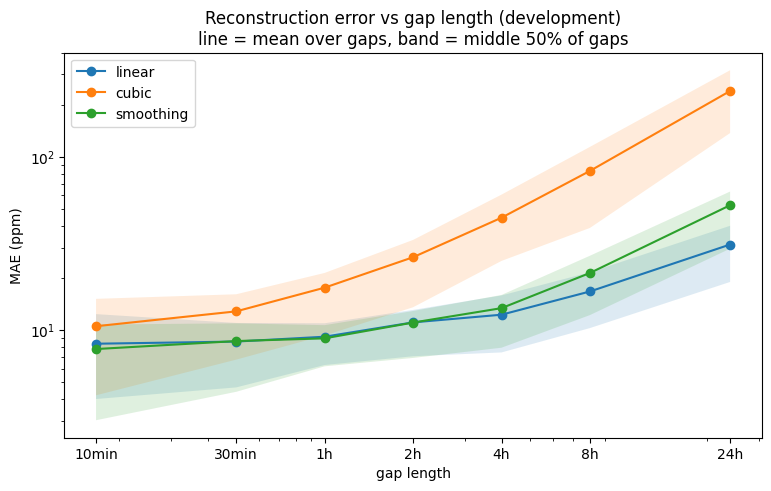

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
lengths = results["gap_length"].drop_duplicates().sort_values()     # same order as the tables
hours = (lengths.dt.total_seconds() / 3600).to_numpy()
for method in METHODS:
    per_gap = results[results["method"] == method].groupby("gap_length")["mae"]
    ax.plot(hours, dev_mae[method], marker="o", label=method)
    ax.fill_between(hours, per_gap.quantile(0.25).to_numpy(), per_gap.quantile(0.75).to_numpy(), alpha=0.15)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(hours); ax.set_xticklabels([fmt(g) for g in lengths])
ax.set_xlabel("gap length"); ax.set_ylabel("MAE (ppm)")
ax.set_title("Reconstruction error vs gap length (development)\nline = mean over gaps, band = middle 50% of gaps")
ax.legend(); plt.show()

### 5.1 Paired comparison: how often does one method beat another on the same gap?
Averages can be dominated by a few very bad gaps. Because every method filled the same gaps, they can be compared gap
by gap: the share of gaps where the first method has a smaller MAE than the second.

In [12]:
per_gap_mae = results.pivot_table(index=["gap_length", "gap_start"], columns="method", values="mae")
pairs = [("linear", "cubic"), ("linear", "smoothing"), ("smoothing", "cubic")]
wins = pd.DataFrame({f"{a} beats {b}": (per_gap_mae[a] < per_gap_mae[b]).groupby("gap_length").mean()
                     for a, b in pairs})
(100 * wins).rename(index=fmt).round(0)   # percent of gaps

,linear beats cubic,linear beats smoothing,smoothing beats cubic
gap_length,,,
10min,68.0,44.0,62.0
30min,77.0,44.0,72.0
1h,86.0,42.0,80.0
2h,86.0,46.0,84.0
4h,94.0,55.0,94.0
8h,96.0,67.0,92.0
24h,100.0,78.0,92.0


> ✍️ As noted before, the cubic is by far the worst performer and is to be expected from the noisy data. Perhaps what wasn't to be expected, is the trend that as gap length rises, linear appears to become more accurate than the smoothing method. 

---
## 6. Bias and physical plausibility (development only)
Low average error is not the only requirement (notes 3.4.16):
- **bias**: mean of (estimate − truth). Positive means the method over-estimates on average;
- **% gaps with overshoot**: share of gaps where some estimate goes above the highest, or below the lowest, context reading used;
- **max overshoot**: the largest such excursion, in ppm;
- **% gaps below `PLAUSIBLE_MIN`**: share of gaps with an estimate below the plausibility threshold.

In [13]:
grouped = results.groupby(["gap_length", "method"])
plausibility = pd.DataFrame({
    "mean bias (ppm)": grouped["bias"].mean(),
    "% gaps with overshoot": 100 * grouped["max_overshoot"].apply(lambda x: (x > 0).mean()),
    "median overshoot (ppm)": grouped["max_overshoot"].median(),
    "max overshoot (ppm)": grouped["max_overshoot"].max(),
    f"% gaps below {PLAUSIBLE_MIN} ppm": 100 * grouped["min_estimate"].apply(lambda x: (x < PLAUSIBLE_MIN).mean()),
    "lowest estimate (ppm)": grouped["min_estimate"].min(),
}).unstack("method").rename(index=fmt)
plausibility.round(1)

mean bias (ppm)                  % gaps with overshoot         \
method               cubic linear smoothing                 cubic linear   
gap_length                                                                 
10min                 -0.0   -0.2      -0.5                   8.5    0.0   
30min                  0.3    0.3       0.4                  24.5    0.0   
1h                     0.8    0.4       0.2                  48.5    0.0   
2h                     1.3    0.1       0.3                  66.0    0.0   
4h                     1.6    1.7       1.9                  84.0    0.0   
8h                     2.2    0.6       1.9                  94.5    0.0   
24h                   -2.1   -2.6      -1.4                  99.0    0.0   

                     median overshoot (ppm)                   \
method     smoothing                  cubic linear smoothing   
gap_length                                                     
10min            0.0                    0.0    0.0       0.0   
30min            0.0                    0.0    0.0       0.0   
1h               0.5                    0.0    0.0       0.0   
2h               2.5                   10.0    0.0       0.0   
4h              20.5                   34.1    0.0       0.0   
8h              52.5                   84.8    0.0       1.3   
24h             88.0                  342.0    0.0      33.0   

           max overshoot (ppm)                  % gaps below 400 ppm         \
method                   cubic linear smoothing                cubic linear   
gap_length                                                                    
10min                      7.9    0.0       0.0                  0.0    0.0   
30min                     31.3    0.0       0.0                  0.5    0.0   
1h                        55.8    0.0       4.4                  1.0    0.0   
2h                        83.2    0.0       4.0                  8.0    0.0   
4h                       156.4    0.0      28.2                 20.5    0.0   
8h                       452.9    0.0      72.6                 36.5    0.0   
24h                     1172.7    0.0     275.1                 57.5    0.0   

                     lowest estimate (ppm)                   
method     smoothing                 cubic linear smoothing  
gap_length                                                   
10min            0.0                 417.5  422.5     427.3  
30min            0.0                 378.7  412.0     423.4  
1h               0.0                 386.9  418.4     422.2  
2h               0.0                 343.1  421.1     426.3  
4h               0.0                 266.6  416.3     414.2  
8h               1.5                 122.2  417.7     388.2  
24h             21.5                -746.7  420.5     204.9

> ✍️ As noted before, the cubic sturggles, especially with overshoot and undershoot. However what is interesting is that the smoothing method tends to overshoot as well as gap length increases. This overshoot aligns with the previous observation that the smoothing method loses accuracy compared linear interpolation as gap lengtrh increases.

---
## 7. Sensitivity to the settings (development only)
These are the choices still open in the decisions log. Fewer gap lengths are used (`SENS_GAP_LENGTHS`) to keep the run short.

**Note:** changing `context` also changes which gap positions are allowed, because a gap needs enough regular readings on
each side. So results for different contexts are on slightly different sets of gaps. Within one context, all methods
still use the same gaps.

In [14]:
SENS_GAP_LENGTHS = ["30min", "2h", "8h"]

def sensitivity(name, values, methods, **fixed):
    """Rerun the experiment for each value of one setting; return mean MAE per gap length."""
    out = {}
    for v in values:
        r = evaluate(dev, SENS_GAP_LENGTHS, methods, **{**SETTINGS, **fixed, name: v})
        r["gap_length"] = pd.to_timedelta(r["gap_length"])
        label = fmt(v) if isinstance(v, pd.Timedelta) else str(v)
        out[label] = r.groupby(["gap_length", "method"])["mae"].mean()
    # Combine first (rows stay in time order), then relabel the gap lengths for display.
    return pd.DataFrame(out).rename(index=fmt, level="gap_length").rename_axis(columns=name)

### 7.1 Context: how much data each side of the gap (D6)
Starts at 1 h. A gap is only allowed if it has at least 3 readings within the context on each side
(`MIN_SIDE_READINGS` in `gapfill.py`). With a 30 min context that rules out about two-thirds of the positions,
because any missed reading nearby leaves a side with too few. So a 30 min result would be on a very different set of gaps.

In [15]:
t0 = time.perf_counter()
CONTEXTS = [pd.Timedelta(c) for c in ["1h", "2h", "4h"]]
by_context = sensitivity("context", CONTEXTS, METHODS).unstack("method")
display(by_context.reindex([fmt(g) for g in SENS_GAP_LENGTHS]).round(1))   # unstack sorts rows A-Z; put them back in time order
print(f"{time.perf_counter() - t0:.0f} s")

context       1h                     2h                     4h         \
method     cubic linear smoothing cubic linear smoothing cubic linear   
gap_length                                                              
30min       12.5    8.5       8.2  13.3    8.7       8.4  13.3    8.4   
2h          28.2   11.3      11.6  28.0   11.3      11.3  28.0   11.2   
8h          87.4   18.6      26.1  84.5   18.0      22.9  83.4   18.9   

context               
method     smoothing  
gap_length            
30min            8.4  
2h              11.3  
8h              22.5

7 s


### 7.2 Cubic spline end condition (D12)
The end condition acts at the outer edges of the context window, not at the gap itself. Its effect fades quickly towards
the middle, so it is expected to matter mainly when the context is short. It is therefore checked with the shortest
context too (1 h – see 7.1 for why not 30 min).

In [16]:
for ctx in [pd.Timedelta("1h"), CONTEXT]:
    print(f"context = {fmt(ctx)}")
    display(sensitivity("bc_type", BC_TYPES, ["cubic"], context=ctx).droplevel("method").round(2))

context = 1h


bc_type,not-a-knot,natural,clamped
gap_length,,,
30min,12.48,12.51,12.49
2h,28.24,28.46,28.56
8h,87.43,88.13,88.44


context = 2h


bc_type,not-a-knot,natural,clamped
gap_length,,,
30min,13.33,13.33,13.33
2h,28.01,28.01,28.01
8h,84.51,84.51,84.51


### 7.3 Smoothing amount `lam` (D10)
`None` lets GCV choose it automatically for each gap. Fixed values from very little smoothing (close to the exact cubic
spline) to a lot (close to a straight line). Time is in hours (D11), so these values only mean something on that scale.
Takes roughly 20 s.

In [17]:
t0 = time.perf_counter()
LAM_VALUES = [None, 0.001, 0.01, 0.1, 1.0, 10.0]
display(sensitivity("lam", LAM_VALUES, ["smoothing"]).droplevel("method").round(1))
print(f"{time.perf_counter() - t0:.0f} s")

lam,None,0.001,0.01,0.1,1.0,10.0
gap_length,,,,,,
30min,8.7,9.7,8.3,8.4,8.9,10.0
2h,12.2,16.4,12.2,11.3,11.6,12.7
8h,27.1,43.9,28.5,22.9,20.3,18.8


10 s


> ✍️ Lam value of 0.1 will  be chosen, as it retains a lower MAE as gap size increases to 8h while keeping a relatively low MAE during other gap lengths. 

---
## 8. Computational cost
Time per fill, from the main experiment (includes Python overhead, so treat it as a rough comparison).

In [18]:
cost = results.groupby("method")["fill_seconds"].agg(["mean", "median", "max"]) * 1000
cost.columns = ["mean (ms)", "median (ms)", "max (ms)"]
cost.loc[list(METHODS)].round(2)

,mean (ms),median (ms),max (ms)
method,,,
linear,0.57,0.54,1.73
cubic,0.67,0.65,1.57
smoothing,1.24,1.19,3.04


> ✍️ This could potentially be a deciding factor. Linear interpolation and smoothing have stayed roughly comparable in performance thusfar, however here we see that the computational cost of smoothing far outweighs that of linear interpolation. 

---
## 8.1 Computational performance (development only)
The brief (section 6) asks for performance to be analysed with **timing routines and profilers**, explained with
**FLOP and arithmetic-intensity estimates**, and for the baseline and selected solutions to be
compared. Order of work: **predict** the cost on paper (8.1.1), **measure** it (8.1.2), **find where the time goes**
with a profiler (8.1.3), then check **scaling** (8.1.4), **memory** (8.1.5) and **repeatability** (8.1.6), and finish
with a **baseline vs selected** summary (8.1.7).

Timings depend on the computer, so they are only meaningful on the machine that ran them (recorded below).

In [19]:
import os, platform, timeit, cProfile, pstats, tracemalloc
import scipy
from scipy.interpolate import CubicSpline, make_smoothing_spline
from mma3001.gapfill import context_readings

print(f"Machine: {platform.platform()} | {platform.processor() or 'processor not reported'} | {os.cpu_count()} logical CPUs")
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

def best_ms(fn, number=200, repeat=5):
    """Time fn with timeit: run it `number` times, `repeat` times over, and keep the fastest
    repeat (the least disturbed by other programs). Returns milliseconds per call."""
    return 1000 * min(timeit.repeat(fn, number=number, repeat=repeat)) / number

def auto_ms(fn):
    """Like best_ms, but timeit chooses how many runs it needs (at least 0.2 s in total)."""
    number, total = timeit.Timer(fn).autorange()
    return 1000 * total / number

Machine: Windows-10-10.0.26200-SP0 | Intel64 Family 6 Model 183 Stepping 1, GenuineIntel | 24 logical CPUs
Python 3.10.5 | numpy 2.2.6 | pandas 2.3.3 | scipy 1.15.3


### 8.1.1 Predicted cost: FLOPs per gap
>
Let *n* = context readings (about 24 with a 2 h context) and *m* = hidden readings (6 for a 1 h gap, 48 for 8 h).

| Method | Work done | FLOPs (approx.) | 8 h gap, n ≈ 24, m = 48 |
|---|---|---|---|
| Linear | For each hidden reading: find its two neighbours (a binary search – comparisons, not FLOPs), then y = y₀ + (x − x₀)(y₁ − y₀)/(x₁ − x₀) | ≈ 5m | ≈ 250 |
| Cubic spline | Build a tridiagonal system for the n knots (≈ 5n), solve it (banded/Thomas, ≈ 8n), form the cubic coefficients (≈ 10n), then evaluate each hidden point with Horner's rule (≈ 7m) | ≈ 25n + 7m | ≈ 1,000 |
| Smoothing, fixed λ | Build banded B-spline matrices and solve **one** 5-diagonal (pentadiagonal) system | ≈ 100n + 10m | ≈ 3,000 |
| Smoothing, GCV λ | As above, but SciPy's bounded search (`minimize_scalar`) tries about **16–25** values of λ, each needing a banded solve, a banded Cholesky inverse and a trace | ≈ 20 × (fixed λ) | ≈ 60,000 |

**What this predicts:**
1. Cost order: linear < cubic < smoothing (fixed λ) ≪ smoothing (GCV), with GCV roughly 10–20× fixed λ.
2. Even 60,000 FLOPs at about 10⁹–10¹⁰ FLOP/s for one core (see notes 2.1.3 for your machine) is only **~10–60 µs**.
   Section 8 measured about 0.5–5 ms per fill, i.e. **10–100× more than the arithmetic needs**.
3. **Arithmetic intensity:** about 24 points × 16 bytes is a few hundred bytes, which sits in the CPU cache. So the fills
   are limited neither by FLOP rate nor by memory bandwidth, but by **overhead**: Python function calls and pandas
   index handling. The profiler (8.1.3) should show this.

### 8.1.2 Measured cost: where does the time of one fill go?
One 8 h gap from the development data, timed with `timeit` (notes 2.1.8). The **maths only** rows run the bare
NumPy/SciPy routine on plain arrays; the **whole `fill_gap`** rows include finding the context readings and building
pandas objects.

In [20]:
gl = pd.Timedelta("8h")
start = valid_gap_starts(dev, gl, CONTEXT, MAX_SPACING)[1000]          # any valid gap will do
observed, truth = make_gap(dev, start, gl)
before, after = context_readings(observed, truth.index, CONTEXT)
known = pd.concat([before, after])
x = (known.index - known.index[0]).total_seconds().to_numpy() / 3600   # hours, as in fill_gap
x_new = (truth.index - known.index[0]).total_seconds().to_numpy() / 3600
y = known.to_numpy()
print(f"{len(known)} context readings, {len(truth)} hidden readings, gap starting {start:%d %b %H:%M}")

steps = {
    "make_gap (copy the series without the gap)": lambda: make_gap(dev, start, gl),
    "context_readings (find the context)": lambda: context_readings(observed, truth.index, CONTEXT),
    "maths only: linear (np.interp)": lambda: np.interp(x_new, x, y),
    "maths only: cubic (CubicSpline)": lambda: CubicSpline(x, y, bc_type=BC_TYPE)(x_new),
    f"maths only: smoothing, lam={LAM}": lambda: make_smoothing_spline(x, y, lam=LAM)(x_new),
    "maths only: smoothing, lam=None (GCV)": lambda: make_smoothing_spline(x, y, lam=None)(x_new),
}
for m in METHODS:
    steps[f"whole fill_gap: {m}"] = lambda m=m: fill_gap(observed, truth.index, m, CONTEXT, lam=LAM, bc_type=BC_TYPE)

timing = pd.Series({name: best_ms(fn) for name, fn in steps.items()}, name="ms per call")
timing.round(4).to_frame()

17 context readings, 37 hidden readings, gap starting 09 Mar 14:25


,ms per call
make_gap (copy the series without the gap),0.1309
context_readings (find the context),0.1892
maths only: linear (np.interp),0.0009
maths only: cubic (CubicSpline),0.0774
"maths only: smoothing, lam=0.1",0.4996
"maths only: smoothing, lam=None (GCV)",3.5507
whole fill_gap: linear,0.4433
whole fill_gap: cubic,0.5919
whole fill_gap: smoothing,1.0702


> ✍️ Here it can be seen that much although there are other factors that contribute to the time to call, the maths associated with smoothing is still large. Crucially, the maths asociated with an automatic lam vs lam = 0.1 reinforces the notion that lam = 0.1 is the more appropriate choice if smoothing is to be chosen. Even so, the computational costs of linear are still far less than either smoothing result. 

### 8.1.3 Profiling the experiment
`cProfile` (Python's built-in profiler) records every function called while `evaluate` fills 100 gaps of 2 h with
all three methods. **Own time** is time spent inside a function itself; **including called functions** adds
everything it calls. (Notes 2.1.9 use `line_profiler` and Scalene for the same purpose; `cProfile` needs no install.)

In [21]:
prof = cProfile.Profile()
prof.enable()
evaluate(dev, ["2h"], METHODS, **{**SETTINGS, "n_gaps": 100})
prof.disable()

stats = pstats.Stats(prof)
prof_df = pd.DataFrame([
    {"function": f"{os.path.basename(file)}:{func}", "calls": n_calls,
     "own time (s)": own, "incl. called functions (s)": incl}
    for (file, line, func), (_, n_calls, own, incl, _) in stats.stats.items()
])
print(f"Total profiled time: {stats.total_tt:.2f} s\n")
print("Where the time is actually spent (largest own time):")
display(prof_df.sort_values("own time (s)", ascending=False).head(12).round(3))
print("The project's own functions (time including everything they call):")
display(prof_df[prof_df["function"].str.startswith("gapfill.py")]
        .sort_values("incl. called functions (s)", ascending=False).round(3))

Total profiled time: 0.74 s

Where the time is actually spent (largest own time):


,function,calls,own time (s),incl. called functions (s)
239,datetimelike.py:_cmp_method,2604,0.036,0.116
520,~:<built-in method builtins.isinstance>,224379,0.034,0.061
486,~:<method 'reduce' of 'numpy.ufunc' objects>,13005,0.021,0.021
399,gapfill.py:context_readings,600,0.015,0.316
231,datetimelike.py:_get_getitem_freq,2705,0.014,0.032
401,gapfill.py:evaluate,1,0.014,0.741
452,_bsplines.py:_coeff_of_divided_diff,2103,0.013,0.014
236,datetimelike.py:_isnan,3206,0.013,0.015
443,_index.py:_validate_indices,1800,0.012,0.033
517,~:<built-in method builtins.getattr>,90868,0.012,0.014


The project's own functions (time including everything they call):


,function,calls,own time (s),incl. called functions (s)
401,gapfill.py:evaluate,1,0.014,0.741
400,gapfill.py:fill_gap,300,0.006,0.452
399,gapfill.py:context_readings,600,0.015,0.316
398,gapfill.py:make_gap,100,0.002,0.038
397,gapfill.py:valid_gap_starts,1,0.000,0.007


> ✍️ Here we see that the prokects own funcitons dominate the processing time when looking at the included called functions. Potential room for improvement, however may also just be necessary as they are required to call that many functions to achieve the task. These project-built functions are likely handling far more complex tasks than inbuilt python functions.

### 8.1.4 Scaling
Two separate questions:
1. **Method cost vs number of context readings n** (maths only). The estimates in 8.1.1 grow in proportion to n, so on a
   log–log plot the lines should run parallel to the dashed O(n) line. Real development readings are used as the data.
2. **Cost of one fill vs the length of the whole series.** A fill only needs about 24 readings, so ideally its cost
   should *not* depend on how long the series is. If it does, the gap-filling code would slow down on the full
   8-month dataset for reasons that have nothing to do with the method.

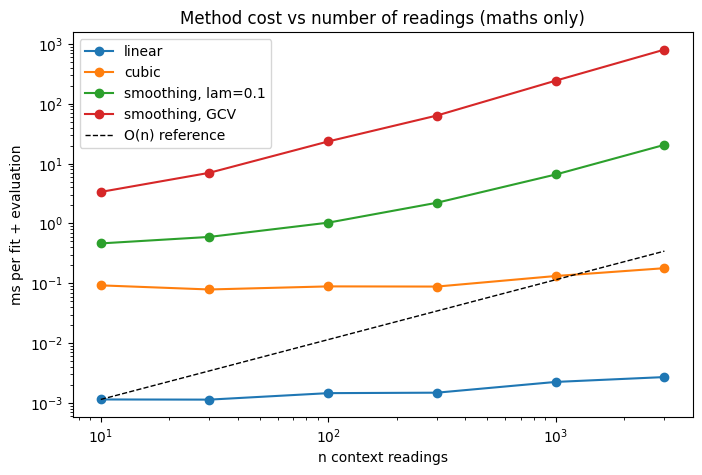

,linear,cubic,"smoothing, lam=0.1","smoothing, GCV"
n context readings,,,,
10,0.0011,0.0924,0.4638,3.3583
30,0.0011,0.0789,0.5952,7.0059
100,0.0015,0.0888,1.0306,23.4177
300,0.0015,0.0882,2.2146,63.3517
1000,0.0023,0.1324,6.5707,242.7996
3000,0.0027,0.1788,20.5185,799.2400


In [22]:
N_VALUES = [10, 30, 100, 300, 1000, 3000]
scaling = {}
for n in N_VALUES:
    part = dev.iloc[:n]
    xs = (part.index - part.index[0]).total_seconds().to_numpy() / 3600
    ys = part.to_numpy()
    xq = np.linspace(xs[0], xs[-1], 50)
    scaling[n] = {
        "linear": auto_ms(lambda: np.interp(xq, xs, ys)),
        "cubic": auto_ms(lambda: CubicSpline(xs, ys, bc_type=BC_TYPE)(xq)),
        f"smoothing, lam={LAM}": auto_ms(lambda: make_smoothing_spline(xs, ys, lam=LAM)(xq)),
        "smoothing, GCV": auto_ms(lambda: make_smoothing_spline(xs, ys, lam=None)(xq)),
    }
scaling = pd.DataFrame(scaling).T.rename_axis("n context readings")

ax = scaling.plot(marker="o", logx=True, logy=True, figsize=(8, 5))
ref = scaling.iloc[0].min() * np.array(N_VALUES) / N_VALUES[0]
ax.plot(N_VALUES, ref, "k--", linewidth=1, label="O(n) reference")
ax.set_ylabel("ms per fit + evaluation"); ax.set_title("Method cost vs number of readings (maths only)")
ax.legend(); plt.show()
scaling.round(4)

In [23]:
# Cost of filling the SAME gap when the series around it is shorter or longer.
start0 = valid_gap_starts(dev.iloc[:1000], gl, CONTEXT, MAX_SPACING)[200]
rows = []
for N in [1000, 2500, 5000, len(dev)]:
    part = dev.iloc[:N]
    obs_N, truth_N = make_gap(part, start0, gl)
    rows.append({"series length": N,
                 "make_gap (ms)": auto_ms(lambda: make_gap(part, start0, gl)),
                 "context_readings (ms)": auto_ms(lambda: context_readings(obs_N, truth_N.index, CONTEXT)),
                 "whole fill_gap, linear (ms)": auto_ms(lambda: fill_gap(obs_N, truth_N.index, "linear", CONTEXT))})
pd.DataFrame(rows).set_index("series length").round(4)

,make_gap (ms),context_readings (ms),"whole fill_gap, linear (ms)"
series length,,,
1000,0.0954,0.2027,0.4008
2500,0.1415,0.1553,0.4183
5000,0.1121,0.1716,0.4280
10251,0.1314,0.2076,0.4336


> ✍️ A single fill does get slower as the series length increases, however not by a significant amount. Further, although the smoothed lam = 01 costs are still greater than that of linear, both do not show significant increase in computational time when the no. readings is increased.

### 8.1.5 Memory
`tracemalloc` (Python's built-in memory tracer) records the **peak extra memory** allocated while one fill runs.

In [24]:
def peak_kb(fn):
    """Peak extra memory (kB) allocated while fn runs."""
    tracemalloc.start()
    fn()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024

memory = {"make_gap": peak_kb(lambda: make_gap(dev, start, gl))}
for m in METHODS:
    memory[f"fill_gap: {m}"] = peak_kb(lambda m=m: fill_gap(observed, truth.index, m, CONTEXT, lam=LAM, bc_type=BC_TYPE))
print(f"For scale: the development series uses {dev.memory_usage(deep=True) / 1024:.0f} kB, "
      f"the results table {results.memory_usage(deep=True).sum() / 1024:.0f} kB")
pd.Series(memory, name="peak extra memory (kB)").round(1).to_frame()

For scale: the development series uses 418 kB, the results table 655 kB


,peak extra memory (kB)
make_gap,182.1
fill_gap: linear,42.3
fill_gap: cubic,42.4
fill_gap: smoothing,42.4


> ✍️ Here make_gap dominates the memory usage, I see no substantial differentiator between the different method functions themselves.

### 8.1.6 Repeatability: does the conclusion depend on which random gaps were drawn?
**The seed check.** `SEED` decides *which* random gap positions are used. If the conclusions (which method is best at
each gap length, and how error grows) are real, they should not change when a different random set of 200 gaps is
drawn. This reruns the main experiment with other seeds, on development data only. `SEED` itself stays at its fixed
value for everything else, including the test.

In [25]:
SEEDS = [0, 1, 2]
by_seed = {}
for s in SEEDS:
    r = results if s == SEED else evaluate(dev, GAP_LENGTHS, METHODS, **{**SETTINGS, "seed": s})
    by_seed[s] = table(r.assign(gap_length=pd.to_timedelta(r["gap_length"])), "mae")

print("Mean absolute error (ppm) for each seed:")
display(pd.concat(by_seed, axis=1, names=["seed", "method"]).round(1))
best = pd.DataFrame({f"seed {s}": t.idxmin(axis=1) for s, t in by_seed.items()})
print("Best method at each gap length, for each seed:")
best

Mean absolute error (ppm) for each seed:


seed            0                       1                       2         \
method     linear  cubic smoothing linear  cubic smoothing linear  cubic   
gap_length                                                                 
10min         8.3   10.5       7.8    8.8   10.5       8.6    7.7    9.5   
30min         8.6   12.8       8.6    8.4   13.7       8.3    8.9   13.4   
1h            9.2   17.6       9.0    9.5   18.6       9.2    9.3   19.2   
2h           11.1   26.4      11.1   10.1   27.6      10.0   10.2   28.6   
4h           12.3   44.6      13.4   12.6   47.2      13.5   13.3   47.3   
8h           16.7   83.1      21.4   19.0   81.9      23.3   17.8  101.0   
24h          31.2  240.5      52.6   29.0  263.2      56.2   31.4  249.4   

seed                  
method     smoothing  
gap_length            
10min            7.4  
30min            8.9  
1h               8.9  
2h              10.4  
4h              14.6  
8h              21.9  
24h             55.7

Best method at each gap length, for each seed:


,seed 0,seed 1,seed 2
gap_length,,,
10min,smoothing,smoothing,smoothing
30min,linear,smoothing,smoothing
1h,smoothing,smoothing,smoothing
2h,smoothing,smoothing,linear
4h,linear,linear,linear
8h,linear,linear,linear
24h,linear,linear,linear


> ✍️ Largely repeatable, we do see some discrepancy in the 2h gap length across seeds/ runs however largely the experiment's repeatability appears strong. 

### 8.1.7 Baseline vs selected solution
The comparison the brief asks for (section 6): the **baseline** (linear), the **original** spline methods
(exact cubic, and smoothing with automatic λ), and the **selected** setting, on accuracy, plausibility and cost.

In [26]:
gcv = evaluate(dev, GAP_LENGTHS, ["smoothing"], **{**SETTINGS, "lam": None})
gcv["gap_length"] = pd.to_timedelta(gcv["gap_length"])
variants = {
    "linear (baseline)": results[results["method"] == "linear"],
    "cubic spline (exact)": results[results["method"] == "cubic"],
    "smoothing, GCV lam (original)": gcv,
    f"smoothing, lam={LAM} (selected)": results[results["method"] == "smoothing"],
}
SHOW = ["30min", "2h", "8h", "24h"]
summary = {}
for name, r in variants.items():
    mae = r.groupby("gap_length")["mae"].mean()
    row = {f"MAE {fmt(k)} (ppm)": v for k, v in mae.items() if fmt(k) in SHOW}
    long_gaps = r[r["gap_length"] == pd.Timedelta("8h")]
    row[f"% 8h gaps below {PLAUSIBLE_MIN} ppm"] = 100 * (long_gaps["min_estimate"] < PLAUSIBLE_MIN).mean()
    row["mean time per fill (ms)"] = 1000 * r["fill_seconds"].mean()
    summary[name] = row
pd.DataFrame(summary).T.round(2)

,MAE 30min (ppm),MAE 2h (ppm),MAE 8h (ppm),MAE 24h (ppm),% 8h gaps below 400 ppm,mean time per fill (ms)
linear (baseline),8.59,11.08,16.72,31.22,0.0,0.57
cubic spline (exact),12.83,26.36,83.09,240.48,36.5,0.67
"smoothing, GCV lam (original)",8.19,11.77,24.90,61.95,2.0,6.30
"smoothing, lam=0.1 (selected)",8.64,11.06,21.39,52.64,1.5,1.24


> ✍️ Here, it actually appears that linear carries a lower MAE while having a mean time per fill that is a fraction of the smoothing, even with lam = 0.1

---
## 9. Final test – run once
Only when every setting in section 1 is final and recorded in the report. Then set `RUN_TEST = True`, run **all** cells
from the top (so the settings in use are the ones shown), and report what comes out, good or bad. If a setting is
changed after this, the test data is no longer a fair test (notes 5.6.6).

In [27]:
if RUN_TEST:
    final = evaluate(test, GAP_LENGTHS, METHODS, **SETTINGS)
    final["gap_length"] = pd.to_timedelta(final["gap_length"])
    test_mae = table(final, "mae")
    print("Mean absolute error (ppm): development vs test")
    display(pd.concat({"development": dev_mae, "test": test_mae}, axis=1).round(1))
    print("% gaps with overshoot on the test data:")
    display((100 * final.groupby(["gap_length", "method"])["max_overshoot"]
             .apply(lambda x: (x > 0).mean()).unstack()[list(METHODS)]).rename(index=fmt).round(0))
else:
    print("Test data not used. Set RUN_TEST = True only once every choice above is final (report D1).")

Mean absolute error (ppm): development vs test


development                    test                 
method          linear  cubic smoothing linear  cubic smoothing
gap_length                                                     
10min              8.3   10.5       7.8    7.1    9.0       6.5
30min              8.6   12.8       8.6    8.0   12.4       7.5
1h                 9.2   17.6       9.0    8.3   16.6       7.8
2h                11.1   26.4      11.1    8.5   25.4       8.4
4h                12.3   44.6      13.4   10.2   43.5      10.9
8h                16.7   83.1      21.4   12.7   85.8      17.2
24h               31.2  240.5      52.6   20.0  236.9      40.3

% gaps with overshoot on the test data:


method,linear,cubic,smoothing
gap_length,,,
10min,0.0,12.0,0.0
30min,0.0,36.0,0.0
1h,0.0,52.0,0.0
2h,0.0,76.0,0.0
4h,0.0,88.0,12.0
8h,0.0,96.0,48.0
24h,0.0,100.0,86.0


> ✍️ A positive factor to note about these results is that as a general trend, the test results do not appear to be siginificantly higher than the development data. This is a positive sign as it means that the model retained physical plausability against data it had never seen before and that the model did not overfit the data. Furthermore, the MAE seemed to follow the same trends on the test data as it did on the development data (such as the MAE starting lower but increasing with gap length for the smoothing model). 

However, one important factor to note as seen in section 3.1, is that the test data does appear to be smoother and with less deviation and noise than the development data. This essentially gives the model an "easy test", and therefore the results could potentially be optimistic.

Testing the baseline (linear), against cubic and two variants of smoothing, I was expecting that the smoothing model would perform better in terms of accuracy but trade off with computational cost. However, in many respects (such as MAE across various gap lengths), it appears that the linear method in fact displays accuracy that is comparable or even superior to the smoothing model (the cubic model was far less accurate than either). Pair this with the substantially more expensive computational coosts of the smoothing models vs linear, and I believe the clear choice for this project is the baseline, linear method, ---
## Summary

> ✍️ 